# 04 · Power and planning

**Question.** Before the Starter Bonus test starts: what is the smallest lift worth detecting, how many players do we need to detect it, how long will that take, and how should the live page compress that time so a visitor sees a verdict in 60–90 seconds?

**Milestone.** M1 · **Theory notes:** [power-mde](../docs/theory/power-mde.md), [variance-reduction](../docs/theory/variance-reduction.md), [anytime-valid](../docs/theory/anytime-valid.md)

## Where we are

Notebook 03 showed the always-valid interval keeps its promise however often we look. What it did not settle is **how far the experiment may run**. That one number, the maximum sample $N_{\max}$, does three jobs:

1. it is where the page stops and says "inconclusive";
2. it is the planned size $N^\star$ the interval is tuned to;
3. it decides what "inconclusive" means: any lift worth having would very likely have shown up by then.

We size it for the analysis the page actually runs: the always-valid interval on the **CUPAC-adjusted** estimate (notebook 01 found pre-sign-up signals remove about 12.6% of the variance; notebook 06 builds the adjustment).

## 1. Model

### The smallest lift worth detecting comes from money

Under the standard schedule, a player's 40 coins for level 5 are paid only if they reach level 10. The Starter Bonus pays them at level 5, so the extra cost is the 40 coins given to activated players who never reach level 10. Each extra activation, in turn, is worth the net margin $V$ that an activated player brings over their life.

With control activation $p_C$, a share $q$ of activated players reaching level 10, and bonus value $b$, the lift at which the bonus pays for itself solves

$$
\Delta^\star V = (p_C + \Delta^\star)(1 - q)\, b
\quad\Longrightarrow\quad
\Delta^\star = \frac{p_C (1-q)\, b}{V - (1-q)\, b}.
$$

We call $\Delta^\star$ the **break-even lift** and size the test to detect it with 80% power.

### Fixed horizon: the textbook sample size

For a one-look test at level $\alpha$ with power $1-\beta$, the players needed **per arm** are approximately

$$
n = \frac{\big(z_{1-\alpha/2} + z_{1-\beta}\big)^2 \,\big[p_C(1-p_C) + p_T(1-p_T)\big]}{\Delta^2}.
$$

Regression adjustment with a covariate that explains a share $R^2$ of the variance multiplies this by $1 - R^2$.

### Sequential: no formula, so we simulate

For the always-valid interval there is no closed-form sample size. We simulate many experiments for each true lift and record (a) the chance of reaching "ship" before $N_{\max}$, which is the sequential power, and (b) how many players that typically takes. We then pick the smallest $N_{\max}$ that gives 80% power at the break-even lift.

With CUPAC the adjustment coefficient $\theta$ comes from an earlier cohort, so it is fixed before the test. The adjusted outcome $\tilde Y = Y - \theta(\hat p(X) - \bar{\hat p})$ is just another per-player number with the same mean difference and variance scaled by $1 - R^2$; the always-valid interval applies to it unchanged.

## 2. Libraries

| Library | Used for |
|---|---|
| `statsmodels` | `NormalIndPower` and `proportion_effectsize`: fixed-horizon sample size, the textbook reference |
| `scipy.stats` | Normal quantiles for the closed-form check |
| `numpy` | Simulating sequential experiments (Gaussian increments per batch, common random numbers across designs) |
| `pandas`, `matplotlib`, `seaborn` | Tables and figures |

The always-valid functions are those from notebook 03 (checked against `gbstats`), repeated here until they move into `ablab`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy.stats import norm
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

from ablab.viz import use_style, savefig, CONTROL, TREAT, INK, MUTED, SHIP, STOP, GOLD_CMAP

use_style()
pd.set_option("display.precision", 3)

SEED = 20261015
ALPHA, POWER = 0.05, 0.80
print(f"seed = {SEED}")


def rho2_for(n_star, alpha=ALPHA):
    a = -2 * np.log(alpha)
    return (a + np.log(a + 1)) / n_star


def cs_multiplier(n, rho2, alpha=ALPHA):
    t = n * rho2
    return np.sqrt(2 * (t + 1) / t * np.log(np.sqrt(t + 1) / alpha))

seed = 20261015


### Planning inputs

The economics are fictional but plausible, and live in the config next to the simulator. Change them and every number below follows.

In [2]:
PLAN = {
    "baseline": 0.22,             # p_C, from notebook 01
    "cupac_r2": 0.126,            # variance removed by CUPAC, notebook 01 (week-1 model scored on week 2)
    "bonus_usd": 0.40,            # 40 coins at $0.01
    "p_reach_level10": 0.55,      # q: activated players who go on to level 10
    "value_per_activation": 2.50, # V: lifetime net margin of an activated player, USD
    "signups_per_hour": 300,      # traffic, notebook 01
    "outcome_delay_h": 72,        # activation is observed 72 h after sign-up
    "min_players": 1_000,         # no verdict before this, notebooks 02-03
}
p_c, q, b, V = PLAN["baseline"], PLAN["p_reach_level10"], PLAN["bonus_usd"], PLAN["value_per_activation"]
BREAK_EVEN = p_c * (1 - q) * b / (V - (1 - q) * b)
F_ADJ = 1 - PLAN["cupac_r2"]
print(f"break-even lift Δ* = {BREAK_EVEN * 100:.2f} points;  CUPAC variance factor = {F_ADJ:.3f}")

break-even lift Δ* = 1.71 points;  CUPAC variance factor = 0.874


## 3. Data

### The economics of the bonus

In [3]:
lifts = np.linspace(0, 0.05, 101)
extra_cost = (p_c + lifts) * (1 - q) * b       # per 1 treated player
extra_value = lifts * V
econ = pd.DataFrame({"lift_points": lifts * 100, "extra_value": extra_value * 1000,
                     "extra_cost": extra_cost * 1000, "net_per_1000": (extra_value - extra_cost) * 1000})
econ.iloc[::20]

,lift_points,extra_value,extra_cost,net_per_1000
0,0.0,0.0,39.6,-39.6
20,1.0,25.0,41.4,-16.4
40,2.0,50.0,43.2,6.8
60,3.0,75.0,45.0,30.0
80,4.0,100.0,46.8,53.2
100,5.0,125.0,48.6,76.4


### Simulating sequential experiments

1,000 experiments per true lift, a look every 250 players (125 per arm), up to 160,000 players. Per batch, the sum of outcomes in each arm is drawn from its normal approximation. The adjusted design reuses the same random draws scaled by $\sqrt{1-R^2}$ (common random numbers), so differences between designs are not noise.

In [4]:
R, B_ARM = 1_000, 125
N_LIMIT = 160_000
T = N_LIMIT // (2 * B_ARM)
LIFTS_PP = [0, 0.5, 1.0, 1.5, round(BREAK_EVEN * 100, 2), 2.0, 2.5, 3.0, 4.0, 5.0]
n_looks = np.arange(1, T + 1) * 2 * B_ARM

rng = np.random.default_rng(SEED)
shocks = rng.standard_normal((R, T)).cumsum(1)  # shared across lifts and designs


def paths(lift, f):
    """Estimate and SE at each look for R experiments; f = variance factor (1 or 1 - R^2)."""
    v = (p_c * (1 - p_c) + (p_c + lift) * (1 - p_c - lift)) * f   # per-player variance, both arms
    k = np.arange(1, T + 1)
    d = lift + shocks * np.sqrt(v * B_ARM) / (B_ARM * k)
    se = np.sqrt(v / (B_ARM * k))
    return d, se


def first_ship(d, se, n_max, min_n=PLAN["min_players"]):
    lo = d - cs_multiplier(n_looks, rho2_for(n_max)) * se
    hit = (lo > 0) & (n_looks >= min_n) & (n_looks <= n_max)
    shipped = hit.any(1)
    return shipped, np.where(shipped, n_looks[hit.argmax(1)], np.nan)


# Sanity check against notebook 03 (exact binomial simulation): +2 points, N* = 20,000, unadjusted -> about 73%.
d, se = paths(0.02, 1.0)
print(f"check vs notebook 03: power at +2 points, N_max = 20,000: {first_ship(d, se, 20_000)[0].mean():.1%}")

check vs notebook 03: power at +2 points, N_max = 20,000: 73.1%


## 4. Descriptives

### Fixed horizon (one look)

In [5]:
def fixed_n_total(lift, f=1.0):
    h = proportion_effectsize(p_c + lift, p_c)
    per_arm = NormalIndPower().solve_power(effect_size=h, alpha=ALPHA, power=POWER, ratio=1)
    return 2 * per_arm * f


def fixed_n_closed_form(lift, f=1.0):
    za, zb = norm.ppf(1 - ALPHA / 2), norm.ppf(POWER)
    v = p_c * (1 - p_c) + (p_c + lift) * (1 - p_c - lift)
    return 2 * (za + zb) ** 2 * v / lift**2 * f


fixed = pd.DataFrame({
    "statsmodels (Cohen's h)": [fixed_n_total(BREAK_EVEN), fixed_n_total(BREAK_EVEN, F_ADJ)],
    "closed form": [fixed_n_closed_form(BREAK_EVEN), fixed_n_closed_form(BREAK_EVEN, F_ADJ)],
}, index=["unadjusted", "CUPAC-adjusted"]).round(0)
fixed

,statsmodels (Cohen's h),closed form
unadjusted,18993.0,18991.0
CUPAC-adjusted,16600.0,16598.0


### Sequential: power at the break-even lift, for each maximum sample

In [6]:
N_GRID = np.arange(10_000, N_LIMIT + 1, 5_000)
seq_rows = []
for design, f in [("unadjusted", 1.0), ("CUPAC-adjusted", F_ADJ)]:
    d, se = paths(BREAK_EVEN, f)
    for n_max in N_GRID:
        seq_rows.append({"design": design, "n_max": n_max, "power": first_ship(d, se, n_max)[0].mean()})
seq = pd.DataFrame(seq_rows)
N_MAX = {design: int(g.loc[g.power >= POWER, "n_max"].min()) for design, g in seq.groupby("design")}
N_FIXED = {"unadjusted": fixed.loc["unadjusted", "closed form"], "CUPAC-adjusted": fixed.loc["CUPAC-adjusted", "closed form"]}
plan = pd.DataFrame({
    "fixed horizon N": N_FIXED,
    "sequential N_max (80% power)": N_MAX,
}).assign(**{"price of peeking ×": lambda t: t.iloc[:, 1] / t.iloc[:, 0]})
plan

,fixed horizon N,sequential N_max (80% power),price of peeking ×
unadjusted,18991.0,35000,1.843
CUPAC-adjusted,16598.0,30000,1.807


### At that maximum: power and players to verdict, for every true lift

In [7]:
N_PLAN = N_MAX["CUPAC-adjusted"]
rows = []
for lift_pp in LIFTS_PP:
    for design, f in [("unadjusted", 1.0), ("CUPAC-adjusted", F_ADJ)]:
        shipped, n_at = first_ship(*paths(lift_pp / 100, f), N_PLAN)
        rows.append({"true lift (points)": lift_pp, "design": design, "power": shipped.mean(),
                     "median players at ship": np.nanmedian(n_at) if shipped.any() else np.nan,
                     "25th pct": np.nanpercentile(n_at, 25) if shipped.any() else np.nan,
                     "75th pct": np.nanpercentile(n_at, 75) if shipped.any() else np.nan})
oc = pd.DataFrame(rows)
oc.pivot(index="true lift (points)", columns="design", values=["power", "median players at ship"]).round(3)

power            median players at ship           
design             CUPAC-adjusted unadjusted         CUPAC-adjusted unadjusted
true lift (points)                                                            
0.00                        0.007      0.007                21000.0    21000.0
0.50                        0.050      0.046                18000.0    16250.0
1.00                        0.295      0.260                19000.0    19500.0
1.50                        0.711      0.634                17000.0    17625.0
1.71                        0.837      0.779                14750.0    16000.0
2.00                        0.942      0.916                12625.0    14000.0
2.50                        0.994      0.985                 9250.0    10250.0
3.00                        1.000      1.000                 7000.0     7750.0
4.00                        1.000      1.000                 4750.0     5000.0
5.00                        1.000      1.000                 3500.0     3875.0

### From players to calendar time, and to seconds on the page

A player enters the analysis 72 hours after signing up, so the verdict time is the time to sign up the players **plus** 72 hours.

The brief asks for one refresh every 2–3 seconds and a verdict in 60–90 seconds for the default preset. With each refresh as **one** experiment hour, the 72-hour delay alone would take about 3 minutes. Two ways out, compared below (median seconds, at 2.5 s per refresh):

- **A. The visitor joins at launch** and each refresh stands for several hours. The first 72 hours show players arriving but no results yet.
- **B. The visitor joins at hour 72**, as the first outcomes come in. Three days of sign-ups are already on the lanes, and the verdict line starts moving straight away.

In [8]:
PAGE_PRESETS = {"No effect": 0.0, "Small real effect": 0.02, "Large effect": 0.05}
SECONDS_PER_TICK = 2.5
TICK_HOURS = [1, 2, 3, 4, 6, 8]


def hours_to_verdict(lift):
    shipped, n_at = first_ship(*paths(lift, F_ADJ), N_PLAN)
    n_end = np.where(shipped, n_at, N_PLAN)   # no verdict: runs to N_max, then "inconclusive"
    return n_end / PLAN["signups_per_hour"] + PLAN["outcome_delay_h"], shipped


def page_seconds(start_hour):
    """Median seconds to a verdict if the visitor joins the experiment at `start_hour`."""
    t = pd.DataFrame(index=TICK_HOURS, columns=list(PAGE_PRESETS), dtype=float)
    for preset, lift in PAGE_PRESETS.items():
        h, _ = hours_to_verdict(lift)
        for th in TICK_HOURS:
            t.loc[th, preset] = np.median(h - start_hour) / th * SECONDS_PER_TICK
    t.index.name = "experiment hours per refresh"
    return t


timing = page_seconds(0)
timing_preroll = page_seconds(PLAN["outcome_delay_h"])
pd.concat({"A. visitor joins at launch": timing, "B. visitor joins at hour 72": timing_preroll}, axis=1).round(0)

A. visitor joins at launch                    \
                                              No effect Small real effect   
experiment hours per refresh                                                
1                                                 430.0             290.0   
2                                                 215.0             145.0   
3                                                 143.0              97.0   
4                                                 108.0              73.0   
6                                                  72.0              48.0   
8                                                  54.0              36.0   

                                          B. visitor joins at hour 72  \
                             Large effect                   No effect   
experiment hours per refresh                                            
1                                   209.0                       250.0   
2                                   105.0                       125.0   
3                                    70.0                        83.0   
4                                    52.0                        62.0   
6                                    35.0                        42.0   
8                                    26.0                        31.0   

                                                             
                             Small real effect Large effect  
experiment hours per refresh                                 
1                                        110.0         29.0  
2                                         55.0         15.0  
3                                         37.0         10.0  
4                                         28.0          7.0  
6                                         18.0          5.0  
8                                         14.0          4.0

## 5. Figures

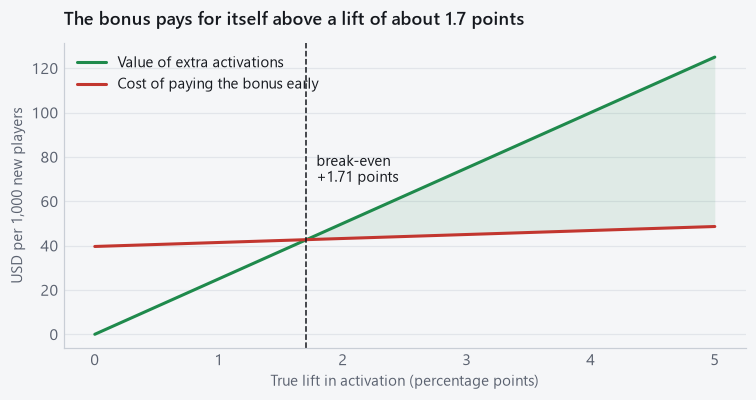

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(econ.lift_points, econ.extra_value, color=SHIP, lw=2, label="Value of extra activations")
ax.plot(econ.lift_points, econ.extra_cost, color=STOP, lw=2, label="Cost of paying the bonus early")
ax.axvline(BREAK_EVEN * 100, color=INK, ls="--", lw=1)
ax.text(BREAK_EVEN * 100 + 0.08, econ.extra_value.max() * 0.55, f"break-even\n+{BREAK_EVEN * 100:.2f} points",
        fontsize=9.5, color=INK)
ax.fill_between(econ.lift_points, econ.extra_cost, econ.extra_value, where=econ.extra_value > econ.extra_cost,
                color=SHIP, alpha=0.1, lw=0)
ax.set_xlabel("True lift in activation (percentage points)")
ax.set_ylabel("USD per 1,000 new players")
ax.set_title("The bonus pays for itself above a lift of about 1.7 points")
ax.legend(loc="upper left")
savefig(fig, "04_break_even")

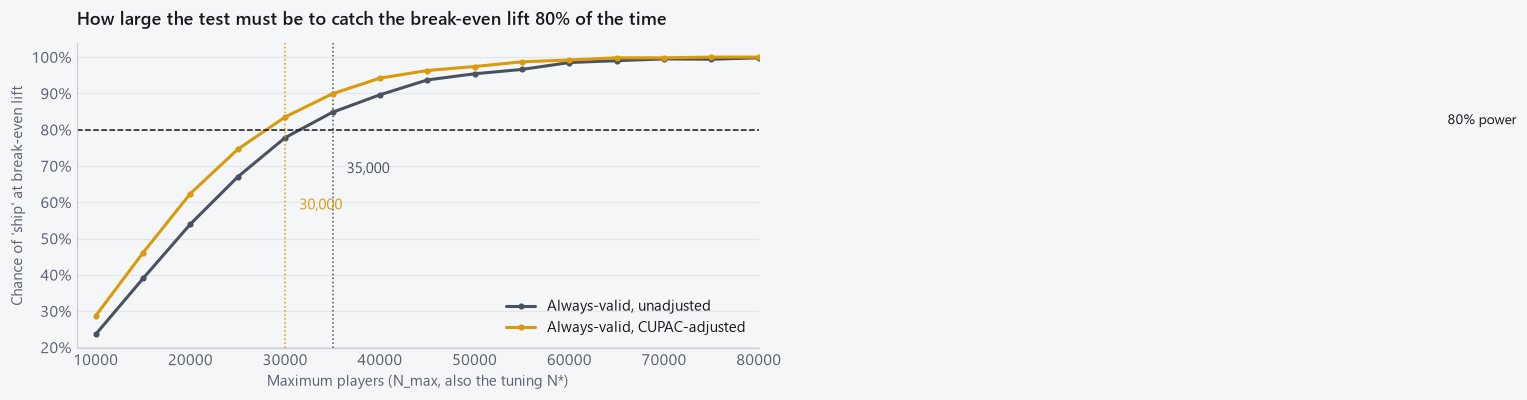

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for design, color in [("unadjusted", CONTROL), ("CUPAC-adjusted", TREAT)]:
    g = seq[seq.design == design]
    ax.plot(g.n_max, g.power, color=color, lw=2, marker="o", ms=3, label=f"Always-valid, {design}")
    ax.axvline(N_MAX[design], color=color, lw=1, ls=":")
ax.axhline(POWER, color=INK, ls="--", lw=1)
ax.text(N_GRID[-1], POWER + 0.015, "80% power", ha="right", fontsize=9, color=INK)
for design, color, dy in [("unadjusted", CONTROL, -0.12), ("CUPAC-adjusted", TREAT, -0.22)]:
    ax.text(N_MAX[design] + 1_500, POWER + dy, f"{N_MAX[design]:,}", color=color, fontsize=9.5)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlim(N_GRID[0] - 2_000, 80_000)
ax.set_xlabel("Maximum players (N_max, also the tuning N*)")
ax.set_ylabel("Chance of 'ship' at break-even lift")
ax.set_title("How large the test must be to catch the break-even lift 80% of the time")
ax.legend(loc="lower right")
savefig(fig, "04_power_vs_nmax")

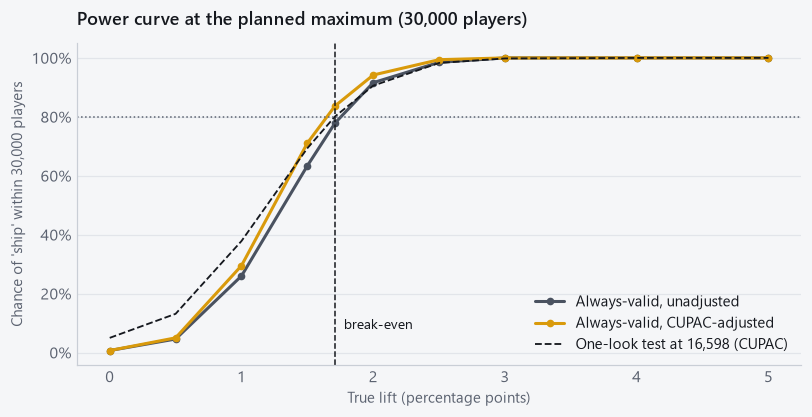

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
# One-look test with CUPAC: same power as an unadjusted test with 1 / F_ADJ times the players.
fh_power = [NormalIndPower().power(effect_size=max(proportion_effectsize(p_c + l / 100, p_c), 1e-9),
                                   nobs1=N_FIXED["CUPAC-adjusted"] / F_ADJ / 2, alpha=ALPHA, ratio=1)
            for l in LIFTS_PP]
for design, color in [("unadjusted", CONTROL), ("CUPAC-adjusted", TREAT)]:
    g = oc[oc.design == design]
    ax.plot(g["true lift (points)"], g.power, color=color, lw=2, marker="o", ms=4, label=f"Always-valid, {design}")
ax.plot(LIFTS_PP, fh_power, color=INK, lw=1.2, ls="--", label=f"One-look test at {N_FIXED['CUPAC-adjusted']:,.0f} (CUPAC)")
ax.axvline(BREAK_EVEN * 100, color=INK, ls="--", lw=1)
ax.axhline(POWER, color=MUTED, ls=":", lw=1)
ax.text(BREAK_EVEN * 100 + 0.07, 0.08, "break-even", fontsize=9, color=INK)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("True lift (percentage points)")
ax.set_ylabel(f"Chance of 'ship' within {N_PLAN:,} players")
ax.set_title(f"Power curve at the planned maximum ({N_PLAN:,} players)")
ax.legend(loc="lower right")
savefig(fig, "04_power_curve")

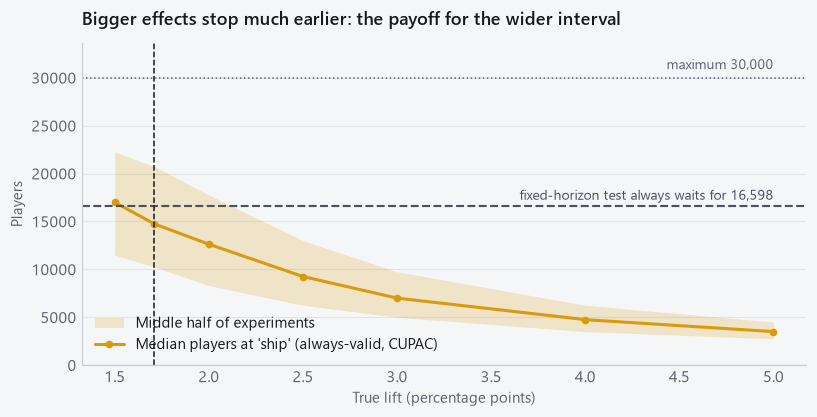

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
g = oc[(oc.design == "CUPAC-adjusted") & (oc["true lift (points)"] >= 1.5)]  # below this few experiments ship
ax.fill_between(g["true lift (points)"], g["25th pct"], g["75th pct"], color=TREAT, alpha=0.2, lw=0,
                label="Middle half of experiments")
ax.plot(g["true lift (points)"], g["median players at ship"], color=TREAT, lw=2, marker="o", ms=4,
        label="Median players at 'ship' (always-valid, CUPAC)")
ax.axhline(N_FIXED["CUPAC-adjusted"], color=CONTROL, ls="--", lw=1.4)
ax.text(5, N_FIXED["CUPAC-adjusted"] * 1.04, f"fixed-horizon test always waits for {N_FIXED['CUPAC-adjusted']:,.0f}",
        ha="right", fontsize=9, color=CONTROL)
ax.axhline(N_PLAN, color=MUTED, ls=":", lw=1)
ax.text(5, N_PLAN * 1.03, f"maximum {N_PLAN:,}", ha="right", fontsize=9, color=MUTED)
ax.axvline(BREAK_EVEN * 100, color=INK, ls="--", lw=1)
ax.set_xlabel("True lift (percentage points)")
ax.set_ylabel("Players")
ax.set_ylim(0, N_PLAN * 1.12)
ax.set_title("Bigger effects stop much earlier: the payoff for the wider interval")
ax.legend(loc="lower left")
savefig(fig, "04_players_to_verdict")

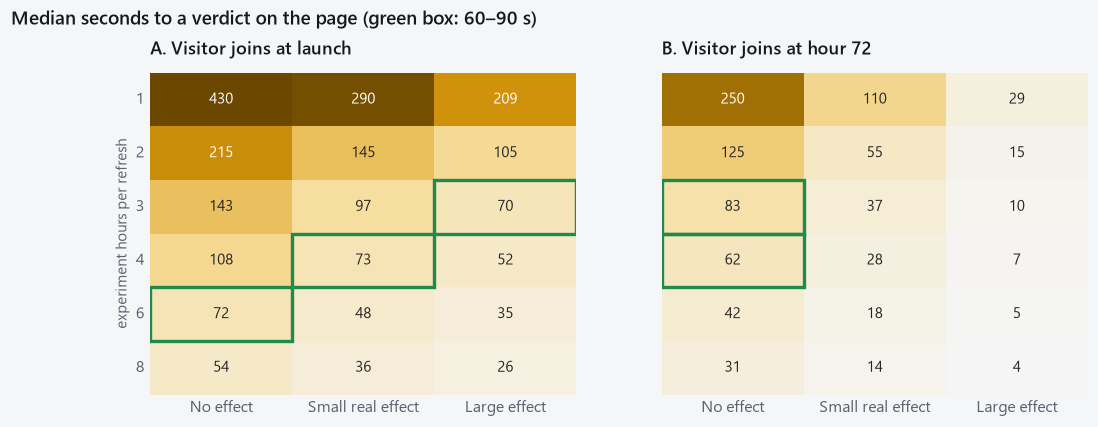

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, t, title in [(axes[0], timing, "A. Visitor joins at launch"),
                     (axes[1], timing_preroll, "B. Visitor joins at hour 72")]:
    sns.heatmap(t, annot=True, fmt=".0f", cmap=GOLD_CMAP, cbar=False, annot_kws={"fontsize": 10}, ax=ax,
                vmin=0, vmax=300)
    for (i, j), v in np.ndenumerate(t.values):
        if 60 <= v <= 90:
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor=SHIP, lw=2.2))
    ax.tick_params(axis="both", rotation=0)
    ax.set_xlabel("")
    ax.set_title(title)
axes[1].set_ylabel("")
fig.suptitle("Median seconds to a verdict on the page (green box: 60–90 s)", x=0.01, ha="left",
             fontweight="semibold", y=1.03)
savefig(fig, "04_page_timing")

## 6. Results

In [14]:
print(f"Break-even lift:                       +{BREAK_EVEN * 100:.2f} points")
for design in ["unadjusted", "CUPAC-adjusted"]:
    print(f"{design:>15}: fixed-horizon N = {N_FIXED[design]:>7,.0f}   sequential N_max = {N_MAX[design]:>7,}"
          f"   ({N_MAX[design] / N_FIXED[design]:.2f}× fixed)")
saving = 1 - N_MAX["CUPAC-adjusted"] / N_MAX["unadjusted"]
days = N_PLAN / PLAN["signups_per_hour"] / 24
print(f"CUPAC saves {saving:.0%} of the maximum sample.")
print(f"Planned maximum: {N_PLAN:,} players = {days:.1f} days of sign-ups + 3 days for outcomes.")

Break-even lift:                       +1.71 points
     unadjusted: fixed-horizon N =  18,991   sequential N_max =  35,000   (1.84× fixed)
 CUPAC-adjusted: fixed-horizon N =  16,598   sequential N_max =  30,000   (1.81× fixed)
CUPAC saves 14% of the maximum sample.
Planned maximum: 30,000 players = 4.2 days of sign-ups + 3 days for outcomes.


- **Size the test to money, not habit.** The Starter Bonus pays for itself above a lift of about 1.7 points, so that is the smallest effect the test must catch. The page's "Small real effect" preset (+2 points) sits just above it.
- **The price of peeking, in players.** The always-valid design needs a larger maximum than a one-look test (table above). In exchange it may stop at any look, and for effects well above break-even it usually stops long before the one-look test would even be allowed to look.
- **CUPAC pays for itself.** Removing 12.6% of the variance cuts the maximum sample by about the same share, which is days of traffic.
- **What "inconclusive" now means.** If the test reaches the maximum without a verdict, a lift worth paying for would have been caught 80% of the time, so the bonus is very likely not worth it.
- **Statistically significant is not the same as profitable.** The verdict ships when the lift is above zero, but between 0 and break-even the bonus loses money. The guardrail (net revenue per player, Milestone 9) is what catches that case.
- **Page timing.** The brief's "one refresh = one hour" cannot meet 60–90 seconds, because of the 72-hour outcome delay. Two options are in the heatmap: (A) start at launch with about 4 experiment hours per refresh, or (B) let the visitor join at hour 72, when the first outcomes arrive, with about 2 hours per refresh. B keeps every second of the visit meaningful; the choice is Daniel's.

## 7. What gets promoted

| Item | Goes to | Guarded by |
|---|---|---|
| `PLAN` economics and traffic | `config/simulator.toml` (`[plan]`) | `tests/test_plan.py`: break-even formula |
| `N_MAX["CUPAC-adjusted"]` as `max_players` and `n_star` | `config/simulator.toml` | `validity/always_valid.py` re-runs evidence 1–3 at this N* |
| Fixed and sequential sample-size functions | `ablab/power.py` | `tests/test_power.py`: closed form vs `statsmodels.NormalIndPower` |
| Power and stopping table | `results/plan.json` | Feeds the *Before the experiment* section |
| Hours per refresh | `config/page.toml` | Notebook 04 timing table |

## 8. Production parity

The planning functions now live in `ablab/power.py` and the inputs in `config/simulator.toml` (`[plan]`, `[page]`).

In [15]:
from ablab import power as prod  # noqa: E402
from ablab.config import load  # noqa: E402

toml = load()
assert abs(prod.break_even_lift(p_c, q, b, V) - BREAK_EVEN) < 1e-12
assert abs(prod.fixed_horizon_n(p_c, BREAK_EVEN, variance_factor=F_ADJ) - N_FIXED["CUPAC-adjusted"]) < 1
assert toml["plan"]["max_players"] == N_PLAN == toml["plan"]["n_star"]
print(f"ablab.power reproduces this notebook; config max_players = n_star = {N_PLAN:,}")

ablab.power reproduces this notebook; config max_players = n_star = 30,000


## Further reading

How many players to plan for, when the test is checked continuously and the decision is economic. Where to find them: **[local]** = `docs/papers/` in this project (kept out of the repo) · **[Vega: folder]** = `Vega/paper-library/pdfs/<folder>/` (Vega's library also has text versions in `paper-library/md/` and notes in `paper-library/papers/`) · **[airline library: folder]** = `Projects/airline-experimentation/paper-library/pdfs/<folder>/` (a copy of Vega's library plus airline-related extras) · **[online]** = not in any library yet. ★ = read first.

Theory notes in this project: [power-mde](../docs/theory/power-mde.md).

- ★ Kohavi, R., Linowski, J., Vermeer, L., Boisseranc, F., Furuseth, J., Gelman, A., Imbens, G., & Rajagopal, R. (2026). Power analysis is essential: high-powered tests suggest minimal to no effect of rounded shapes on click-through rates. *Econ Journal Watch* 23(1). Why underpowered A/B tests mislead. **[Vega: 05-power-and-decisions]**
- ★ Gelman, A., & Carlin, J. (2014). Beyond power calculations: assessing Type S (sign) and Type M (magnitude) errors. *Perspectives on Psychological Science* 9(6). Why a significant result from a small test exaggerates the effect. **[Vega: 05-power-and-decisions]**
- Nordin, M., & Schultzberg, M. (2024). Precision-based designs for sequential randomized experiments. arXiv:2405.03487. Stopping at a target precision. **[Vega: 04-sequential-anytime-valid]**
- Spotify Engineering. *Fixed-Power Designs: It's Not IF You Peek, It's WHAT You Peek At* (blog). The blog version of the above. **[Vega: 04-sequential-anytime-valid]**
- Feit, E. M., & Berman, R. (2019). Test & roll: profit-maximizing A/B tests. *Marketing Science* 38(6). Sample size from profit, not significance; close to this project's break-even. **[Vega: 05-power-and-decisions]**
- Maharaj, A. V., et al. (2023). Anytime-valid confidence sequences in an enterprise A/B testing platform. Section on sample-size planning for confidence sequences. **[local]** `2302.10108v1.pdf`
- Sandorellana. *Sample Size Estimation and Monte Carlo Simulations* (Medium). Power by simulation, as in this notebook. **[airline library: 14-airline-related-topics]**
- Schultzberg, M. *What Makes a Good Sample Size Calculator?* (Confidence blog). Everything that changes the required N. **[Vega: 05-power-and-decisions]** (see `confidence-ssc/`)